<a href="https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/03_grpo_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TrainYourAgent** · [Ch 1 · Q-learning](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/01_q_learning_tool_agent.ipynb) → [Ch 2 · REINFORCE](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb) → **📍 Ch 3 · GRPO** → [Ch 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)

# 👥 Chapter 3 · GRPO from scratch: learn from a *group* of attempts

### The algorithm behind DeepSeek-R1, running on a tiny agent you can see.

REINFORCE (Chapter 2) works, but it has two weaknesses:

1. Its baseline is **one running average for every question**, even though some questions are easier than others.
2. It learns from each episode **once** and then throws it away. If you try to squeeze more out of the data by taking bigger or repeated steps, it can easily **overshoot**.

**GRPO** (*Group Relative Policy Optimization*) fixes these problems with three ideas. It was introduced in the [DeepSeekMath paper](https://arxiv.org/abs/2402.03300) and later used to train **DeepSeek-R1**:

| Idea | In one sentence |
|:--|:--|
| 👥 **Group baseline** | Try the *same* question several times and compare the attempts with each other. |
| ✂️ **Clipping** | Reuse each batch a few times, but never push a choice too far in one go. |
| 🪢 **KL leash** | Stay reasonably close to the starting brain (the *reference*). |

And one more upgrade, to get us closer to LLMs: 📖 **the agent now reads the question.** No more topic labels. Like an LLM, it only sees the words.

✅ Free **CPU** · ✅ About 2 minutes · ✅ PyTorch only

## 1 · The world, now with real sentences 🌍

Same buttons, same tools, same rewards. The questions now come in **different phrasings** ("What is 3 x 4?", "Multiply 6 by 8", "Calculate 5 times 7"...).

In [1]:
import copy
import random
import re
import statistics

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

random.seed(0)
torch.manual_seed(0)

buttons = ["Calculator", "Dictionary", "Reply", "Finish"]

In [2]:
meanings = {
    "orbit": "a path around another object",
    "habitat": "an animal's natural home",
    "planet": "a large body orbiting a star",
    "volcano": "a mountain that erupts lava",
    "gravity": "a force pulling things together",
    "comet": "an icy body with a glowing tail",
}
greetings = {"hello": "Hello!", "thanks": "You're welcome!", "bye": "Goodbye!"}

def use_tool(button, task):
    kind, question, data = task
    if button == "Calculator" and kind == "math":
        return str(data[0] * data[1])
    if button == "Dictionary" and kind == "words":
        return meanings[data]
    if button == "Reply" and kind == "chat":
        return greetings[data]
    return None  # Wrong tool: no answer

In [3]:
practice = [
    ("math", "What is 3 x 4?", (3, 4)),
    ("math", "Multiply 6 by 8", (6, 8)),
    ("math", "Calculate 5 times 7", (5, 7)),
    ("math", "What is 12 x 2?", (12, 2)),
    ("words", "Define orbit", "orbit"),
    ("words", "What does habitat mean?", "habitat"),
    ("words", "Meaning of planet", "planet"),
    ("words", "Define volcano", "volcano"),
    ("chat", "Say hello", "hello"),
    ("chat", "Say thanks to my teacher", "thanks"),
    ("chat", "Please say bye", "bye"),
    ("chat", "Say hello to everyone", "hello"),
]
test_tasks = [  # new numbers, new words, new phrasings
    ("math", "What is 9 x 11?", (9, 11)),
    ("math", "Calculate 4 times 25", (4, 25)),
    ("words", "Define gravity", "gravity"),
    ("words", "What does comet mean?", "comet"),
    ("chat", "Say bye to my friend", "bye"),
    ("chat", "Say thanks", "thanks"),
]

⚠️ Each task still carries its topic (`"math"`), but **only the world uses it** so the calculator knows what to compute. The **agent never sees it**. It gets only the words of the question.

Notice the trap: *"What is 9 x 11?"* (math) and *"What does comet mean?"* (words) both start with **"What"**. The agent has to learn which words actually matter.

## 2 · Teach the agent to read: a tiny tokenizer 📖

LLMs chop text into **tokens** and give each token an id number. We'll do the simplest possible version: **one token per word**. Words the agent has never seen become `<unk>` (unknown).

In [4]:
def words(text):
    return re.findall(r"[a-z]+|\d+", text.lower())

vocab = {"<unk>": 0}
for _, question, _ in practice:
    for w in words(question):
        vocab.setdefault(w, len(vocab))

def encode(question, has_answer):
    ids = torch.tensor([vocab.get(w, 0) for w in words(question)])
    return ids, torch.tensor([float(has_answer)])

print("Vocabulary size:", len(vocab))
print("'What does comet mean?' ->", encode("What does comet mean?", False)[0].tolist())

Vocabulary size: 34
'What does comet mean?' -> [1, 18, 0, 20]


`comet` isn't in the practice questions, so it becomes `0` (`<unk>`). The policy will simply **ignore** unknown words, so it has to rely on *"what"*, *"does"* and *"mean"*.

## 3 · A tiny neural-network policy (our "mini-LLM") 🧠

Instead of a table, the brain is now a small **neural network**:

1. Each word gets a list of 16 numbers (an **embedding**), and we average them into one "meaning of the question". Unknown words (id `0`) are left out of the average.
2. We add one extra number: **1** if the agent already has an answer, **0** if not.
3. A small network turns that into **4 logits** → softmax → probabilities, exactly like Chapter 2.

An LLM does the same thing at a massive scale: tokens in, logits for the next token out.

In [5]:
class TinyPolicy(nn.Module):
    def __init__(self, vocab_size, dim=16, n_actions=4):
        super().__init__()
        self.embed = nn.EmbeddingBag(vocab_size, dim, mode="mean", padding_idx=0)  # unknown words are ignored
        self.head = nn.Sequential(nn.Linear(dim + 1, 32), nn.Tanh(), nn.Linear(32, n_actions))

    def forward(self, observation):
        ids, has_answer = observation
        meaning = self.embed(ids[None])[0]
        return self.head(torch.cat([meaning, has_answer]))  # 4 logits

policy = TinyPolicy(len(vocab))
print("Number of learnable numbers:", sum(p.numel() for p in policy.parameters()))
probs = torch.softmax(policy(encode("What is 9 x 11?", False)), -1)
print("Untrained probabilities:", {b: f"{p:.0%}" for b, p in zip(buttons, probs.tolist())})

Number of learnable numbers: 1252
Untrained probabilities: {'Calculator': '35%', 'Dictionary': '19%', 'Reply': '21%', 'Finish': '25%'}


About a thousand numbers. Qwen2.5-0.5B, the model in Chapter 4, has **hundreds of thousands of times more**, but the idea is identical.

## 4 · Play an episode 🎮

`play` runs one episode and records what the agent **saw** (observations) and what it **did** (actions). We need both later to recompute the log-probs.

In [6]:
def play(policy, task, greedy=False):
    question, has_answer = task[1], False
    observations, actions, total_reward = [], [], 0.0
    for move in range(4):
        obs = encode(question, has_answer)
        with torch.no_grad():
            logits = policy(obs)
        if greedy:
            a = int(logits.argmax())
        else:
            a = int(torch.distributions.Categorical(logits=logits).sample())
        observations.append(obs)
        actions.append(a)

        if buttons[a] == "Finish":
            points, done = (1.0 if has_answer else -1.0), True
        else:
            done = False
            if use_tool(buttons[a], task) is not None:
                points, has_answer = -0.02, True
            else:
                points = -0.15
        if move == 3 and not done:
            points -= 0.5  # Running out of moves is bad
        total_reward += points
        if done:
            break
    return {"obs": observations, "actions": actions,
            "reward": total_reward, "success": bool(done and has_answer)}

In [7]:
attempt = play(policy, practice[0])
print("Question:", practice[0][1])
print("Buttons :", [buttons[a] for a in attempt["actions"]])
print(f"Reward  : {attempt['reward']:+.2f}")

Question: What is 3 x 4?
Buttons : ['Dictionary', 'Finish']
Reward  : -1.15


## 5 · Idea 1: the group baseline 👥

Here is GRPO's key trick. For each question we let the agent try **G times** (a *group*). Then we score every attempt **against its siblings**:

```
advantage = (reward - group average) / group spread
```

- Better than its siblings → **positive** advantage → make those choices more likely.
- Worse than its siblings → **negative** advantage → make them less likely.
- All attempts scored the same → **zero** advantage → nothing to learn from this group.

No separate "critic" network is needed to guess what's usual. The group *is* the baseline. That's why GRPO is popular for LLMs: it saves a whole extra model.

In [8]:
def group_advantages(rewards):
    rewards = torch.tensor(rewards)
    return (rewards - rewards.mean()) / (rewards.std() + 1e-4)

G = 8
task = practice[0]
group = [play(policy, task) for _ in range(G)]
rewards = [g["reward"] for g in group]
advantages = group_advantages(rewards)
print(f"Question: {task[1]}\n")
for i, (g, adv) in enumerate(zip(group, advantages)):
    path = " → ".join(buttons[a] for a in g["actions"])
    print(f"attempt {i}: reward {g['reward']:+.2f} | advantage {adv:+.2f} | {path}")

Question: What is 3 x 4?

attempt 0: reward -1.00 | advantage -0.39 | Finish
attempt 1: reward -0.97 | advantage -0.34 | Reply → Calculator → Dictionary → Dictionary
attempt 2: reward -1.00 | advantage -0.39 | Finish
attempt 3: reward +0.96 | advantage +2.40 | Calculator → Calculator → Finish
attempt 4: reward -0.71 | advantage +0.03 | Dictionary → Calculator → Calculator → Calculator
attempt 5: reward -1.30 | advantage -0.81 | Dictionary → Reply → Finish
attempt 6: reward -0.97 | advantage -0.34 | Dictionary → Reply → Reply → Calculator
attempt 7: reward -0.84 | advantage -0.16 | Calculator → Reply → Calculator → Reply


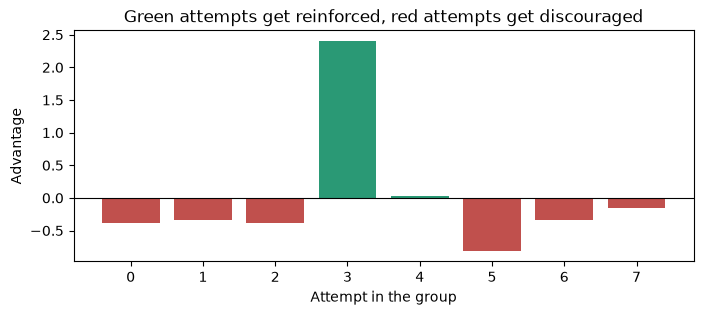

In [9]:
colors = ["#2A9975" if a > 0 else "#C0504D" for a in advantages]
plt.figure(figsize=(8, 3))
plt.bar(range(G), advantages, color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Attempt in the group")
plt.ylabel("Advantage")
plt.title("Green attempts get reinforced, red attempts get discouraged")
plt.show()

## 6 · Idea 2: clipping ✂️

To get more learning out of each batch, GRPO updates on it **several times** (several *epochs*). There's a catch: after the first update the brain has changed, so the batch was collected by a slightly *older* brain.

We measure how much a choice's probability has changed with the **ratio**:

```
ratio = new probability of the choice / old probability of the choice
```

- `ratio = 1.0` → no change yet.
- `ratio = 1.3` → the choice is now 30% more likely than when we collected the data.

**Clipping** says: once the ratio leaves the range **[0.8, 1.2]**, stop pushing in that direction. The plot below shows the effect. The objective goes flat outside the safe zone, so there's no more reward for pushing further.

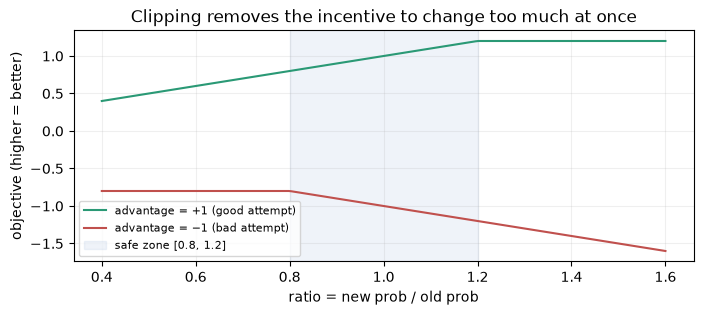

In [10]:
def clipped_objective(ratio, advantage, clip=0.2):
    return torch.min(ratio * advantage, ratio.clamp(1 - clip, 1 + clip) * advantage)

ratios = torch.linspace(0.4, 1.6, 200)
plt.figure(figsize=(8, 3))
plt.plot(ratios, clipped_objective(ratios, torch.tensor(1.0)), label="advantage = +1 (good attempt)", color="#2A9975")
plt.plot(ratios, clipped_objective(ratios, torch.tensor(-1.0)), label="advantage = −1 (bad attempt)", color="#C0504D")
plt.axvspan(0.8, 1.2, color="#3B6FB6", alpha=0.08, label="safe zone [0.8, 1.2]")
plt.xlabel("ratio = new prob / old prob")
plt.ylabel("objective (higher = better)")
plt.title("Clipping removes the incentive to change too much at once")
plt.legend(fontsize=8)
plt.grid(alpha=0.2)
plt.show()

**How to read it:** for a good attempt (green), raising its probability helps, but only up to a ratio of 1.2. After that the line is flat, so the gradient is zero. For a bad attempt (red), lowering its probability helps, but only down to 0.8.

## 7 · Idea 3: the KL leash 🪢

We keep a **frozen copy of the starting brain**, called the *reference*. A small penalty grows whenever the trained brain's probabilities drift away from the reference's. This penalty is called the **KL divergence**.

For LLMs, the reference is the original model. The leash stops it from forgetting how to write good English while it chases reward. GRPO uses this simple estimator, which is always ≥ 0 and exactly 0 when nothing has changed:

```
kl = exp(ref_logp - new_logp) - (ref_logp - new_logp) - 1
```

In [11]:
def kl_penalty(new_logp, ref_logp):
    diff = ref_logp - new_logp
    return torch.exp(diff) - diff - 1

for p_new in [0.25, 0.5, 0.9]:
    kl = kl_penalty(torch.log(torch.tensor(p_new)), torch.log(torch.tensor(0.25)))
    print(f"reference says 25%, new brain says {p_new:.0%} -> penalty {kl:.3f}")

reference says 25%, new brain says 25% -> penalty 0.000
reference says 25%, new brain says 50% -> penalty 0.193
reference says 25%, new brain says 90% -> penalty 0.559


💡 Many recent recipes (for example [DAPO](https://arxiv.org/abs/2503.14476) and [Dr. GRPO](https://arxiv.org/abs/2503.20783)) set the leash strength `beta` to **0** for tasks with a clear right answer. We keep a small leash here so you can see how it works, and you'll test what happens without it.

## 8 · Put it together: one GRPO step 🔧

**1. Recompute log-probs** of the actions an attempt took, under any brain (current or reference):

In [12]:
def logprobs_of(policy, attempt):
    return torch.stack([torch.log_softmax(policy(obs), -1)[a]
                        for obs, a in zip(attempt["obs"], attempt["actions"])])

**2. Collect a batch:** several questions × a group of G attempts each, with group advantages and the *old* log-probs.

In [13]:
def collect_batch(policy, questions, G):
    batch = []
    for task in questions:
        group = [play(policy, task) for _ in range(G)]
        advantages = group_advantages([g["reward"] for g in group])
        for attempt, adv in zip(group, advantages):
            attempt["advantage"] = adv
            with torch.no_grad():
                attempt["old_logp"] = logprobs_of(policy, attempt)
            batch.append(attempt)
    return batch

**3. Update:** a few epochs over the batch with the clipped objective plus the KL leash. *This function is GRPO.*

In [14]:
def grpo_update(policy, reference, optimizer, batch, epochs=4, clip=0.2, beta=0.02):
    for _ in range(epochs):
        losses, kls = [], []
        for attempt in batch:
            new_logp = logprobs_of(policy, attempt)
            with torch.no_grad():
                ref_logp = logprobs_of(reference, attempt)
            ratio = torch.exp(new_logp - attempt["old_logp"])
            objective = clipped_objective(ratio, attempt["advantage"], clip)
            kl = kl_penalty(new_logp, ref_logp)
            losses.append((-objective + beta * kl).mean())  # average over decisions
            kls.append(kl.mean())
        loss = torch.stack(losses).mean()                   # average over attempts
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.stack(kls).mean().item()

## 9 · Before learning: how good is it? 📏

We let the agent sample its choices and test on the **six unseen questions**, 50 times each.

In [15]:
def test_accuracy(policy, questions, repeats=50):
    return sum(play(policy, t)["success"] for t in questions for _ in range(repeats)) / (len(questions) * repeats)

torch.manual_seed(0)
policy = TinyPolicy(len(vocab))
reference = copy.deepcopy(policy).requires_grad_(False)  # frozen starting brain
before = test_accuracy(policy, test_tasks)
print(f"Before training: {before:.0%} of unseen tasks completed")

Before training: 18% of unseen tasks completed


## 10 · Time to train! 🎯

Each iteration: pick **4 questions** → play a **group of 8** attempts for each → run `grpo_update`.

In [16]:
ITERATIONS = 60     # 👈 try 20
G = 8               # 👈 group size: try 2 or 16
QUESTIONS_PER_STEP = 4
BETA = 0.02         # 👈 KL leash strength: try 0.0 or 1.0
CLIP = 0.2

optimizer = torch.optim.Adam(policy.parameters(), lr=0.01)
reward_history, kl_history = [], []
for iteration in range(ITERATIONS):
    questions = random.sample(practice, QUESTIONS_PER_STEP)
    batch = collect_batch(policy, questions, G)
    kl = grpo_update(policy, reference, optimizer, batch, clip=CLIP, beta=BETA)
    reward_history.append(statistics.mean(a["reward"] for a in batch))
    kl_history.append(kl)
    if iteration % 10 == 0 or iteration == ITERATIONS - 1:
        print(f"iteration {iteration:3d} | mean reward {reward_history[-1]:+.2f} | KL {kl:.3f}")

iteration   0 | mean reward -0.49 | KL 0.035


iteration  10 | mean reward +0.76 | KL 0.978


iteration  20 | mean reward +0.78 | KL 1.446


iteration  30 | mean reward +0.98 | KL 0.945


iteration  40 | mean reward +0.98 | KL 0.552


iteration  50 | mean reward +0.92 | KL 1.822


iteration  59 | mean reward +0.98 | KL 0.575


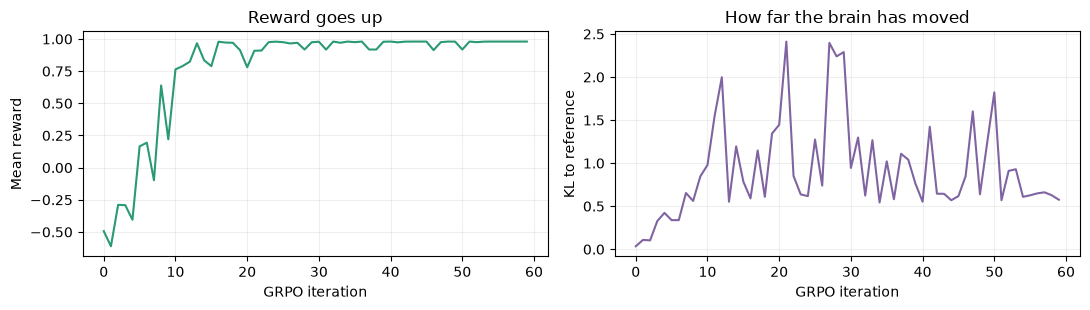

In [17]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
left.plot(reward_history, color="#2A9975")
left.set(xlabel="GRPO iteration", ylabel="Mean reward", title="Reward goes up")
right.plot(kl_history, color="#8064A2")
right.set(xlabel="GRPO iteration", ylabel="KL to reference", title="How far the brain has moved")
for ax in (left, right):
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

The best possible reward is **+0.98** (one useful tool for −0.02, then Finish for +1). Meanwhile the KL rises: the agent pays a small leash penalty to move away from its random starting brain.

## 11 · Did it learn to read? 🏆

These questions were **never seen during practice**, and some contain words that aren't even in the vocabulary.

In [18]:
after = test_accuracy(policy, test_tasks)
print(f"Before: {before:.0%} | After: {after:.0%}\n")
for task in test_tasks:
    attempt = play(policy, task, greedy=True)
    path = " → ".join(buttons[a] for a in attempt["actions"])
    print(f"{task[1]:24} {path:22} {'✅' if attempt['success'] else '❌'}")

Before: 18% | After: 98%

What is 9 x 11?          Calculator → Finish    ✅
Calculate 4 times 25     Calculator → Finish    ✅
Define gravity           Dictionary → Finish    ✅
What does comet mean?    Dictionary → Finish    ✅
Say bye to my friend     Reply → Finish         ✅
Say thanks               Reply → Finish         ✅


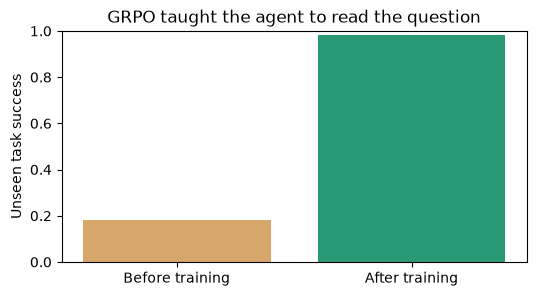

In [19]:
plt.figure(figsize=(6, 3))
plt.bar(["Before training", "After training"], [before, after], color=["#D7A66B", "#2A9975"])
plt.ylim(0, 1)
plt.ylabel("Unseen task success")
plt.title("GRPO taught the agent to read the question")
plt.show()

## 12 · Experiments: what does each GRPO knob do? 🧪

Let's train fresh agents with different settings and compare them on the unseen questions. RL is noisy, so we train **5 agents (seeds) per setting** and report both the **average** and the **worst** agent. This takes about 2 minutes.

In [20]:
def train_grpo(G=8, beta=0.02, clip=0.2, lr=0.01, epochs=4, iterations=60, seed=0):
    random.seed(seed)
    torch.manual_seed(seed)
    policy = TinyPolicy(len(vocab))
    reference = copy.deepcopy(policy).requires_grad_(False)
    optimizer = torch.optim.Adam(policy.parameters(), lr=lr)
    for _ in range(iterations):
        batch = collect_batch(policy, random.sample(practice, 4), G)
        grpo_update(policy, reference, optimizer, batch, epochs, clip, beta)
    return policy

settings = {
    "default (G=8)": {},
    "small group (G=2)": {"G": 2},
    "big group (G=16)": {"G": 16},
    "no leash (beta=0)": {"beta": 0.0},
    "tight leash (beta=1)": {"beta": 1.0},
    "big steps, clipped": {"lr": 0.05, "epochs": 10},
    "big steps, NO clip": {"lr": 0.05, "epochs": 10, "clip": 100.0},
}
results = {}
for name, kwargs in settings.items():
    scores = [test_accuracy(train_grpo(seed=s, **kwargs), test_tasks, 20) for s in range(5)]
    results[name] = scores
    print(f"{name:22} average {statistics.mean(scores):4.0%} | worst {min(scores):4.0%}")

default (G=8)          average  96% | worst  90%


small group (G=2)      average  95% | worst  84%


big group (G=16)       average  99% | worst  98%


no leash (beta=0)      average  99% | worst  98%


tight leash (beta=1)   average  50% | worst  42%


big steps, clipped     average  89% | worst  56%


big steps, NO clip     average  85% | worst  55%


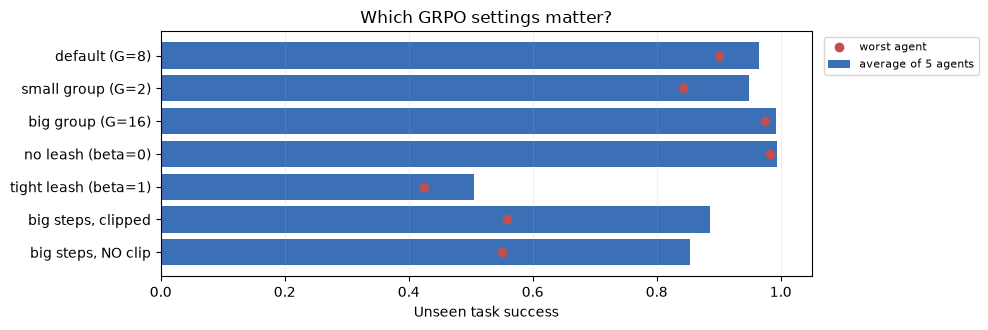

In [21]:
names = list(results)[::-1]
plt.figure(figsize=(10, 3.4))
plt.barh(names, [statistics.mean(results[n]) for n in names], color="#3B6FB6", label="average of 5 agents")
plt.scatter([min(results[n]) for n in names], names, color="#C0504D", zorder=3, label="worst agent")
plt.xlim(0, 1.05)
plt.xlabel("Unseen task success")
plt.title("Which GRPO settings matter?")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.grid(alpha=0.2, axis="x")
plt.tight_layout()
plt.show()

**What you'll typically see** (exact numbers vary from run to run, which is normal in RL):

- **A tight leash (`beta=1`) blocks learning.** The agent keeps getting pulled back toward its random starting brain. This is the clearest effect.
- **Big steps hurt, and clipping is a safety belt, not a cure.** With a 5× higher learning rate and 10 epochs per batch, the agents become less reliable. Clipping usually softens the damage a little: in our runs the clipped version averaged a few points higher. But with a learning rate that is truly too high, *both* versions fail. Picking a sensible step size still matters most.
- **Bigger groups help a little.** With `G=2` there are only two attempts to compare, so the advantages are noisier.
- **No leash (`beta=0`) is fine here.** This toy has a clear right answer, which is also why recent LLM recipes often drop the KL term.

These are the same knobs you'll find in real LLM training configs: `num_generations` (G), `beta`, `epsilon` (clip) and `learning_rate`.

## 13 · From toy GRPO to LLM GRPO 🚀

| In this notebook | In Chapter 4 (a real LLM) |
|:--|:--|
| Question text → word ids | Prompt → tokenizer → token ids |
| `TinyPolicy` (~1k numbers) | Qwen2.5-0.5B-Instruct (~500M numbers) |
| One decision = one button | One decision = one **token** |
| Episode = a few buttons | Episode = a whole answer, including **tool calls and their results** |
| Group of 8 attempts | 8 sampled answers to the same prompt |
| Reward from the world | Reward = **is the final number correct?** |
| Frozen `reference` copy | The original model with LoRA adapters switched off |

There's one genuinely new problem in Chapter 4. When the LLM calls the calculator, the calculator's output gets pasted into the text. Those tokens were written **by the tool, not the model**, so we must **not** train on them. We'll handle that with a **loss mask**.

## 🎓 Congratulations: you implemented GRPO from scratch!

You learned:

- ✅ **Group baselines:** compare several attempts at the same question; no critic network needed.
- ✅ **Ratios and clipping:** reuse data safely without overshooting.
- ✅ **The KL leash:** stay close to a reference brain, and know when you can drop it.
- ✅ **Reading:** a policy that sees only words can generalize to new phrasings.

**Your one-sentence takeaway:** *GRPO makes each attempt compete with its siblings, then nudges the policy toward the winners, carefully.*

### ➡️ Next: [Ch 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)

<a href="https://colab.research.google.com/github/HamedKhosravi99/TrainYourAgent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⭐ Found this useful? [Star TrainYourAgent on GitHub](https://github.com/HamedKhosravi99/TrainYourAgent) so other beginners can find it.